In [1]:
import os
import pandas as pd
import numpy as np
import scipy
#import sklearn

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

In [3]:
from sklearn.metrics import classification_report, f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

In [5]:
base_dir = "/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/data_2022"
inc_dir = "incidenti/csv"

In [14]:
#setting the dataset to be prepared for modelling and validation

def train_test_validation(path, directory):

    inc_dir = os.path.join(path, directory)
    
    df = pd.read_csv(
        os.path.join(inc_dir, "incidenti_2022.csv"),
        encoding="ISO-8859-1",
         header=0
    )

    #print(df.shape)
    #print(df.head())

    #PARSING DATE + FEATURE TEMPORALI

    df["DataOraIncidente"] = pd.to_datetime(
    df["DataOraIncidente"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
    )

    df["hour"] = df["DataOraIncidente"].dt.hour
    df["weekday"] = df["DataOraIncidente"].dt.weekday   # 0=lunedì
    df["month"] = df["DataOraIncidente"].dt.month

    df["TipoVeicolo"] = df["TipoVeicolo"].str.lower()

    #print(df.shape)
    #print(df['TipoVeicolo'].unique())
    #print(df.head())

    
    #CHECK VALORI TIPO VEICOLO
    
    df["TipoVeicolo"] = df["TipoVeicolo"].str.strip()

    #remove non sense values
    df = df[~df["TipoVeicolo"].isin(["1", "2", "3"])]
    df = df[df["TipoVeicolo"].notna()]

    #print(df.shape)
    #print(df['TipoVeicolo'].unique())

    #VEHICLE MAPPING FOR TARGET AND PREDICTION
    
    vehicle_mapping = {
    # auto
    "autovettura privata": "auto", "autovettura pubblica": "auto",
    "autovettura di polizia": "auto", "autovettura di soccorso": "auto",
    "autovettura con rimorchio": "auto", "autoambulanza": "auto",
    "autoambulanza in servizio": "auto", "autocaravan": "auto",
    "autoveicolo trasp.promisc.": "auto", "quadriciclo": "auto",
    "quadriciclo leggero": "auto",
    
    # moto
    "motociclo a solo": "moto", "motociclo con passeggero": "moto",
    "motociclo di polizia": "moto", "ciclomotore": "moto",
    "ciclomotore con passeggero": "moto", "motocarrozzetta": "moto",
    
    # bici / micromobilità
    "velocipede": "bici", "bicicletta elettrica": "bici",
    "monopattino elettrico": "bici", "micromobilità elettrica - hoverboard": "bici",
    "micromobilità elettrica - segway": "bici", "veicolo a braccia": "bici",
    
    # MEZZI PESANTI
    "autocarro inferiore 35 q.": "mezzi_pesanti", "autocarro superiore 35 q.": "mezzi_pesanti",
    "autotreno": "mezzi_pesanti", "autoarticolato": "mezzi_pesanti", "trattore stradale": "mezzi_pesanti",
    "rimorchio": "mezzi_pesanti", "motrice": "mezzi_pesanti", "autogru": "mezzi_pesanti", "macchina operatrice": "mezzi_pesanti",
    
    # autoBUS / trasporto pubblico
    "autobus urbano": "mezzi_pesanti", "autobus di linea": "mezzi_pesanti",
    "autobus in extraurbana": "mezzi_pesanti", "autobus turistico": "mezzi_pesanti",
    "filobus": "mezzi_pesanti", "autosnodato": "mezzi_pesanti", "vettura tranviaria": "mezzi_pesanti",
    
    # altro
    "veicolo speciale": "altro", "veicolo ignoto perchè fuga": "altro", "altro": "altro", "treno": "altro"
}
    
    df["target"] = df["TipoVeicolo"].map(vehicle_mapping)

    #print(df.shape)
    
    df = df[df["target"].notna()]

    print(df.shape)

    #check that the column target has only the value we decided
    #check how many values we have for each category in order to decide which kind of analysis do,
    #and which category to include
    
    #print(df['target'].unique())
    #print(df['target'].value_counts())        
    print(df["target"].value_counts(normalize=True) * 100)

    # Rimuoviamo solo la categoria 'altro'
    df_ml = df[df["target"] != "altro"]
    le = LabelEncoder()
    df_ml["target_encoded"] = le.fit_transform(df_ml["target"])


    features = [
        "hour",
        "weekday",
        "month",
        "TipoStrada",
        "FondoStradale",
        "Pavimentazione",
        "Illuminazione",
        "Segnaletica"
    ]

    x = df_ml[features]
    y = df_ml["target_encoded"]


    #encoding numeric and categorical variables
    num_features = ["hour", "weekday", "month"]
    cat_features = [
        "TipoStrada",
        "FondoStradale",
        "Pavimentazione",
        "Illuminazione",
        "Segnaletica"
    ]

    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median"))
        ]
    )
    
    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, num_features),
            ("cat", categorical_transformer, cat_features)
        ]
    )


    print(x.shape, y.shape)
    x_train, x_test, y_train, y_test = train_test_split(
        x,
        y,
        test_size=0.2,
        stratify=y,
        random_state=42
    )

    print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)
    return(x_train, x_test, y_train, y_test, preprocessor, le)

In [15]:
#Run train_test_validation to check that it returns everything correctly

x_train, x_test, y_train, y_test, preprocessor, le =train_test_validation(base_dir, inc_dir)

(45628, 21)
target
auto             78.758657
moto             12.303849
mezzi_pesanti     6.945297
bici              1.608661
altro             0.383536
Name: proportion, dtype: float64
(45453, 8) (45453,)
(36362, 8) (9091, 8) (36362,) (9091,)


/tmp/ipykernel_468/1373283252.py:7: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(
/tmp/ipykernel_468/1373283252.py:100: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ml["target_encoded"] = le.fit_transform(df_ml["target"])


In [8]:
def logistic_regression(X_train, X_test, y_train, y_test, preprocessor, label_encoder):

    model = LogisticRegression(
        
        max_iter=1000,
        class_weight="balanced",
        n_jobs=-1
    )

    clf = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    y_pred_labels = label_encoder.inverse_transform(y_pred)
    y_test_labels = label_encoder.inverse_transform(y_test)

    return {
        "model": "Logistic Regression",
        "pipeline": clf,
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
        "report": classification_report(y_test_labels, y_pred_labels)
    }

In [9]:
def random_forest(X_train, X_test, y_train, y_test, preprocessor, label_encoder):

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    clf = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    y_pred_labels = label_encoder.inverse_transform(y_pred)
    y_test_labels = label_encoder.inverse_transform(y_test)

    return {
        "model": "Random Forest",
        "pipeline": clf,              
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
        "report": classification_report(y_test_labels, y_pred_labels)
    }

In [10]:
def xgboost(X_train, X_test, y_train, y_test, preprocessor, label_encoder):

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softmax",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    clf = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    y_pred_labels = label_encoder.inverse_transform(y_pred)
    y_test_labels = label_encoder.inverse_transform(y_test)

    return {
        "model": "XGBoost",
        "pipeline": clf,              
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_weighted": f1_score(y_test, y_pred, average="weighted"),
        "report": classification_report(y_test_labels, y_pred_labels)
    }

In [11]:
#MAIN

x_train, x_test, y_train, y_test, preprocessor, le = train_test_validation(base_dir, inc_dir)

results = []

results.append(logistic_regression(x_train, x_test, y_train, y_test, preprocessor, le))
results.append(random_forest(x_train, x_test, y_train, y_test, preprocessor, le))
results.append(xgboost(x_train, x_test, y_train, y_test, preprocessor, le))

for res in results:
    print("\n", res["model"])
    print("Accuracy:", res["accuracy"])
    print("f1_weighted:", res["f1_weighted"])

/tmp/ipykernel_468/4194017633.py:7: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(
/tmp/ipykernel_468/4194017633.py:100: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_ml["target_encoded"] = le.fit_transform(df_ml["target"])
/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/venv_opendata/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['Illuminazione']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


(45628, 21)
(45453, 8) (45453,)
(36362, 8) (9091, 8) (36362,) (9091,)


/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/venv_opendata/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/venv_opendata/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/venv_opendata/l


 Logistic Regression
Accuracy: 0.33208667913320866
f1_weighted: 0.42076604140092394

 Random Forest
Accuracy: 0.5370146298537014
f1_weighted: 0.5946458456752972

 XGBoost
Accuracy: 0.7894621053789462
f1_weighted: 0.7026752160529951


In [12]:
def plot_confusion_matrix(
    clf,
    X_test,
    y_test,
    label_encoder,
    normalize=True,
    title="Confusion Matrix"
):
    """
    Plot confusion matrix for a trained sklearn pipeline
    """

    # Predict
    y_pred = clf.predict(X_test)

    # Decode labels
    y_test_labels = label_encoder.inverse_transform(y_test)
    y_pred_labels = label_encoder.inverse_transform(y_pred)

    # Confusion matrix
    cm = confusion_matrix(
        y_test_labels,
        y_pred_labels,
        labels=label_encoder.classes_
    )

    if normalize:
        cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    # Plot
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f" if normalize else "d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.tight_layout()
    plt.show()

/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/venv_opendata/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['Illuminazione']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/venv_opendata/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['Illuminazione']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
/mnt/d/isabe/Desktop/Progetti_ripresa_lavoro/venv_opendata/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['Illuminazione']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


               precision    recall  f1-score   support

         auto       0.79      1.00      0.88      7187
         bici       0.20      0.01      0.03       147
mezzi_pesanti       0.40      0.01      0.02       634
         moto       0.40      0.01      0.03      1123

     accuracy                           0.79      9091
    macro avg       0.45      0.26      0.24      9091
 weighted avg       0.71      0.79      0.70      9091

Accuracy: 0.7894621053789462
F1 weighted: 0.7026752160529951


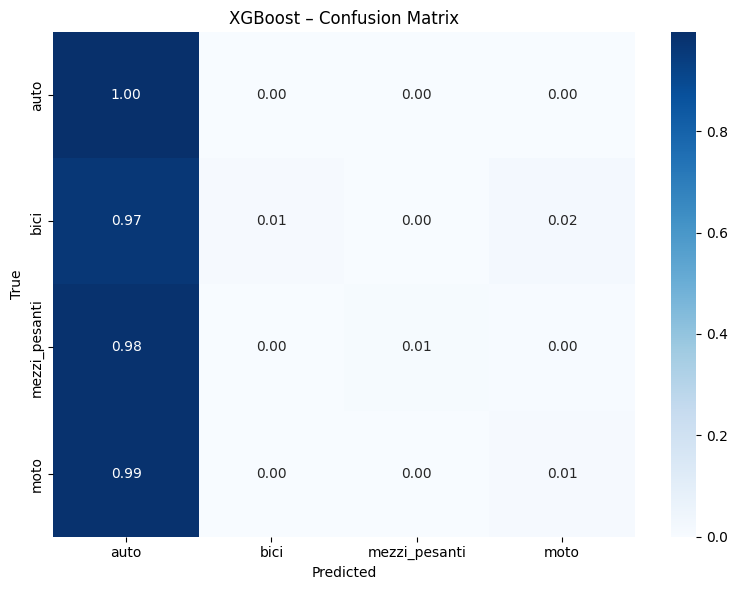

In [13]:
xgb_results = xgboost(
    x_train,
    x_test,
    y_train,
    y_test,
    preprocessor,
    le
)

print(xgb_results["report"])
print("Accuracy:", xgb_results["accuracy"])
print("F1 weighted:", xgb_results["f1_weighted"])

plot_confusion_matrix(
    clf=xgb_results["pipeline"],
    X_test=x_test,
    y_test=y_test,
    label_encoder=le,
    normalize=True,
    title="XGBoost – Confusion Matrix"
)